In [1]:
from pathlib import Path
import os

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "run_flowette.py").exists():
    raise FileNotFoundError(
        "Open this notebook from the extracted project directory, or set PROJECT_ROOT manually."
    )
os.chdir(PROJECT_ROOT)

In [2]:
TASK = "zinc" # Choose from qm9, zinc, moses, guacamol

# Set SMOKE_RUN=True only to verify the installation quickly.
SMOKE_RUN = False
FORCE_RETRAIN = True

if SMOKE_RUN:
    MAX_GRAPHS = 5000
    AE_EPOCHS = 10
    FM_EPOCHS = 50
    NUM_SAMPLES = 200
    SKIP_EVAL = True
else:
    MAX_GRAPHS = 5000 # None
    AE_EPOCHS = 10 # 50
    FM_EPOCHS = 10 # 500
    NUM_SAMPLES = 200 # 1000
    SKIP_EVAL = False

print({
    "task": TASK,
    "max_graphs": MAX_GRAPHS,
    "ae_epochs": AE_EPOCHS,
    "fm_epochs": FM_EPOCHS,
    "samples": NUM_SAMPLES,
})

{'task': 'zinc', 'max_graphs': 5000, 'ae_epochs': 10, 'fm_epochs': 10, 'samples': 200}


In [3]:
from run_flowette import main as run_flowette

argv = [
    "--task", TASK,
    "--max-num-graphs", str(MAX_GRAPHS),
    "--ae-epochs", str(AE_EPOCHS),
    "--fm-epochs", str(FM_EPOCHS),
    "--fm-layers", "5",
    "--pairing-strategy", "online", # auto
    "--pairing-refresh-every", "5",
    "--n-steps", "200",
    "--num-samples", str(NUM_SAMPLES),
]
if FORCE_RETRAIN:
    argv.append("--force-train-fm")
if SKIP_EVAL:
    argv.append("--skip-eval")

generated_molecules, metrics = run_flowette(argv)

[config] task=zinc root=./dataset/ZINC node_feat_dim=9 atom_types=9 formal_charges=None flow_loss=velocity+endpoint+valence+atom_hist
[AE] Loaded ./checkpoints/encoder_zinc_nd64_hd128.pt and ./checkpoints/decoder_zinc_nd64_hd128.pt
[FM objective] shared across all datasets: velocity + endpoint + valence + atom histogram (beta_end=1.0, beta_valence=0.5, beta_atom_hist=0.5)
[FM][online] epoch=1/10 train=0.4117 val=0.3573 | FGW=218.01s model=22.40s overhead=90.7% calls=157
[FM][online] epoch=2/10 train=0.3172 val=0.2049 | FGW=220.27s model=22.37s overhead=90.8% calls=157
[FM][online] epoch=3/10 train=0.1990 val=0.1739 | FGW=215.66s model=22.19s overhead=90.7% calls=157
[FM][online] epoch=4/10 train=0.1741 val=0.1568 | FGW=219.29s model=22.30s overhead=90.8% calls=157
[FM][online] epoch=5/10 train=0.1660 val=0.1501 | FGW=216.26s model=22.43s overhead=90.6% calls=157
[FM][online] epoch=6/10 train=0.1543 val=0.1490 | FGW=219.71s model=22.51s overhead=90.7% calls=157
[FM][online] epoch=7/10 t

In [4]:
from rdkit import Chem

valid_smiles = [
    Chem.MolToSmiles(m, canonical=True, isomericSmiles=True)
    for m in generated_molecules
    if m is not None
]
print(f"Valid decoded molecules: {len(valid_smiles)}/{len(generated_molecules)}")
print("First 200 SMILES:")
for smi in valid_smiles[:200]:
    print(smi)
print("Metrics:", metrics)

Valid decoded molecules: 200/200
First 200 SMILES:
CC(CC1CN=CNCCOC1)=C1CCCNC1
C=C=NC1C=C(CN)C1
C=CCNOCC(=C=CCCCCO)CCO
CC=CCCC(C=CCCN(CCOCC)CC(C)Cl)CNCS
C=CCCC=C=C(C)F
C=CC(O)CC(=C)CCC
CC12CCC3=CCC4CC1NC4(C3)C2
OCCCC1NCCC(O)CN1
ClCC=C1CCCCC=CNC1
CC1=NC23CCC12CN3
CCCC(=CO)C(O)(OCN)N(C)C
N=CN(CN)C1(CCCNCO)C2C=CC3CC(O)=CCC=NCN2C31
C=C=CCC(NC1=CCCC1CNCN)(C(O)=NC)C1NC=CO1
N=CCCC(CNN)C(O)C(CNO)C1N=N1
OCCCCC1=CCC(C=C2COC3CNCN23)=C1
C1=CC(C23NNOC2O3)CNC1
O=COC=C=CC(Br)CCC(F)N1CCNNN1
CN(CC=N)CCC1(F)C=C1
CC1=C(Cl)C1=C(N)C1CNC(C2=CC=C2)NO1
OC1[SH]=C(CCl)CCC=C=C2C=CCNC21
CCC(C(C)CNN)C1CC12CC(CC(C)NN)C2
CCC(CN)C1CC(=C(O)CCC2=C3C=C(C=NO3)C3CCNC2C3)OC=N1
CCCC(Cl)C1(C)CCNC(C2C(O)CNC2ON(C)CN)O1
NC1CCCCCC2C3=C2C(N)C1CS3
CCN(CO)C1CC2(ON1)C1CCC12F
CC=CCC(C1(NC)CC2C=CC1C2)C(C)(C(O)CS)C(Cl)NC
CCC1NC(C(O)OC)C=C(S)CC1NNC1=C=CCNC1
CCC1(N(C)C(C)C)C=CC(Cl)C1(N=CC(O)C1C=CCCCC=CCC1)OCF
C=C(CO)S(S)(CC)C(CCOC)NNCCC
C=CSC(CC=NO)C1CC=C(C(O)ONC)OC1
CCC(C)C1COC(N)C(C(C)=C=C(O)OC)C1
CCC1CCC2(C)C(O)C2(C)C1(C)CO
C=C(C=C(O)C

Saved image at -> images/zinc_generated_molecules_20261002_175352.png


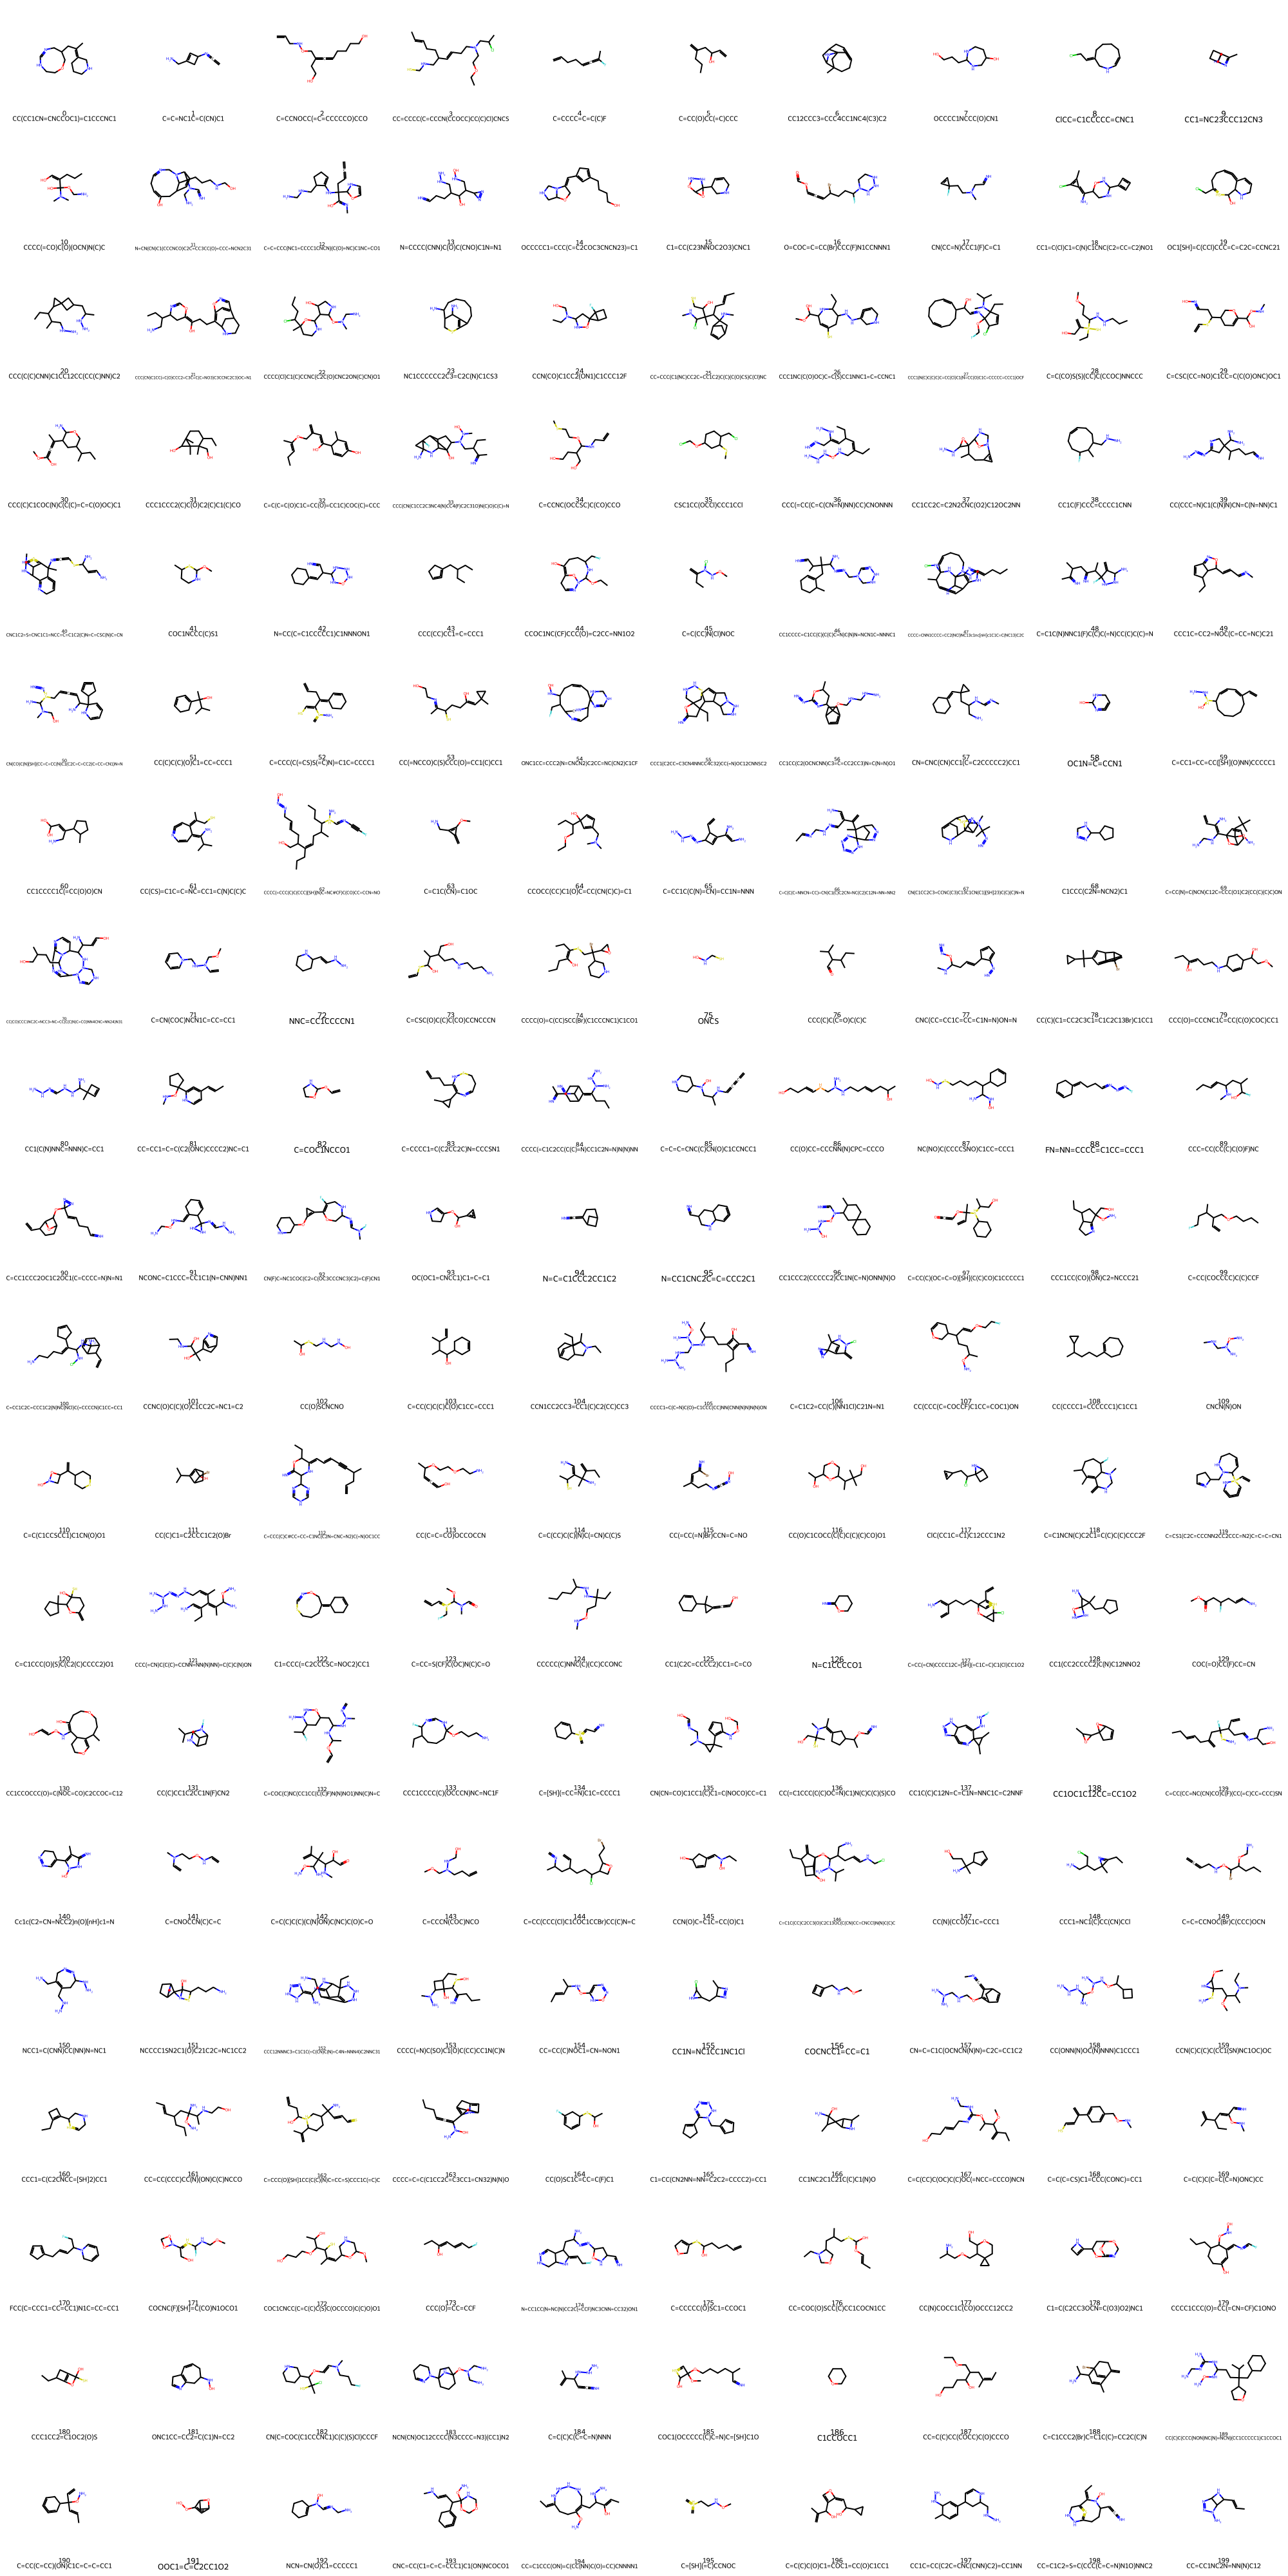

In [5]:
import os
import pandas as pd
from IPython.display import display
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole

IPythonConsole.drawOptions.maxMols = 1000

valid_mols = [m for m in generated_molecules if m is not None]
valid_smiles = [Chem.MolToSmiles(m, canonical=True, isomericSmiles=True) for m in valid_mols]

subset_mols = valid_mols[:200]
subset_smiles = valid_smiles[:200]
legends = [f"{i}\n{smi}" for i, smi in enumerate(subset_smiles)]

img = Draw.MolsToGridImage(
    subset_mols,
    molsPerRow=10,
    subImgSize=(200, 200),
    legends=legends,
    maxMols=1000,
    useSVG=False,
    returnPNG=False,
)

os.makedirs("images", exist_ok=True)
timestamp = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S")

out_path = f"images/{TASK}_generated_molecules_{timestamp}.png"

img.save(out_path)
print(f"Saved image at -> {out_path}")
display(img)

In [6]:
# [k=default] valid=1.000, unique=1.000, novel=1.000, vun=1.000, nspdk=0.103655 # -> nspdk_complexity = 4
# [k=default] valid=1.000, unique=1.000, novel=1.000, vun=1.000, nspdk=0.208272 # -> nspdk_complexity = 2
# [k=default] valid=1.000, unique=1.000, novel=1.000, vun=1.000, nspdk=0.097097 # -> nspdk_complexity = 6